# Supplemental Figure 4, Panel A

Volcano plots showing differential expression due to IFNg or Dex stimulation at 1h or 6h of treatment

*Output: panela_volcano.pdf*

# Setup

In [1]:
#load packages*
library(tidyverse)
library(RColorBrewer)
library(patchwork)
library(ggrastr)
library(here)
here::i_am("figures/SuppFig4/PanelA/PanelA_volcano.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

volcano <- function(table, name, max_x=NULL, max_y=NULL){
    palette <- c(brewer.pal(3,"Paired")[2], "grey", brewer.pal(6, "Paired")[6])
    n <- table(table$change)
    table <- na.omit(table)
    if(is.null(max_x)){
        max_x <- max(abs(table$log2FoldChange))
        }
    if(is.null(max_y)){
       max_y <- max(-log10(table$padj[which(is.finite(-log10(table$padj)))]))
        }
    ggplot(table, aes(x=log2FoldChange,y=-log10(padj))) +
        geom_vline(xintercept=c(-log2(1.5), log2(1.5)), linetype=2) + 
        geom_hline(yintercept=-log10(0.05), linetype=2) +
        rasterize(geom_point(aes(color=change), size=.5), dpi=300) +
        coord_cartesian(xlim=c(-max_x,max_x), ylim=c(0,max_y)) +
        scale_color_manual(values=palette) +
        scale_alpha_manual(values=c(0.5,1)) +
        ggtitle(name, subtitle=paste0("down:",n[1], "; up:", n[3]))
}

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig4/PanelA

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         ggrastr_1.0.2      patchwork_1.3.0    RColorBrewer_1.1-3
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [2]:
#read in DEGs
# read in DEGs
ifn_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "IFNy_1h_DEGs.tsv"),
  sep = "\t"
)

ifn_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "IFNy_6h_DEGs.tsv"),
  sep = "\t"
)

dex_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "Dex_1h_DEGs.tsv"),
  sep = "\t"
)

dex_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "Dex_6h_DEGs.tsv"),
  sep = "\t"
)


# Generate plots

In [3]:
volc_i1 <- volcano(ifn_1h,"IFNy-1h", max_y=80)
volc_i6 <- volcano(ifn_6h,"IFNy-6h", max_y=150)
volc_d1 <- volcano(dex_1h,"Dex-1h", max_x=6)
volc_d6 <- volcano(dex_6h,"Dex-6h", max_y=250)

# Assemble figure panel

Saving 7 x 7 in image


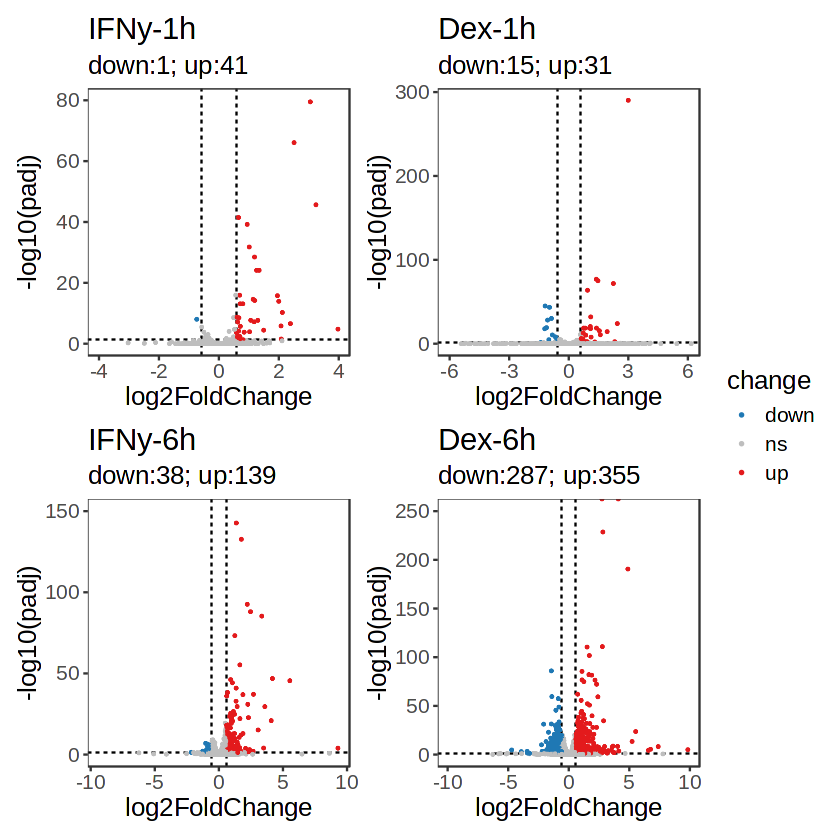

In [4]:
((volc_i1 / volc_i6) | (volc_d1 / volc_d6)) + plot_layout(guides="collect")
ggsave("panela_volcano.pdf")